# DieCasting_analysis.csv 다이캐스팅 공정 불량 분석

1. 데이터 로드 및 기본 점검
2. 데이터 품질 점검 (상수·센서 0값·연속 중복·라벨 충돌)
3. 제품별(Product_Type) 비교
4. 시간 추이 — 불량률 드리프트
5. 단변량 분석 (제품별 정상 vs 불량)
6. 불량 분류 모델 — 랜덤 CV vs 시간 블록 CV
7. 규칙 추출 & 기간 내 검증
8. 시각화

## 1. 데이터 로드 및 기본 점검
행 순서 = 쇼트(shot) 생산 순서로 가정합니다.

In [1]:
import warnings
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

raw = pd.read_csv('../data/DieCasting_analysis.csv')
print(f'데이터 크기: {raw.shape[0]:,}행 × {raw.shape[1]}열')
print(f'결측치 합계: {raw.isna().sum().sum():,}')
print(f'완전 중복 행: {raw.duplicated().sum():,}')
print(f'불량률(Defect=1): {raw.Defect.mean():.1%}  ({raw.Defect.sum():,}건)')
raw.head()

데이터 크기: 7,535행 × 18열
결측치 합계: 0
완전 중복 행: 3,098
불량률(Defect=1): 22.4%  (1,689건)


,Product_Type,Velocity_1,Velocity_2,Velocity_3,High_Velocity,Cylinder_Pressure,Rapid_Rise_Time,Biscuit_Thickness,Clamping_Force,Pressure_Rise_Time,Casting_Pressure,Melting_Furnace_Temp,Air_Pressure,Coolant_Temp,Coolant_Pressure,Factory_Temp,Factory_Humidity,Defect
0,1,0.168,0.170,0.188,2.134,214,0.008,10,258,0.044,1037,695.0,6.3,26.0,2.71,32.9,58.4,0
1,1,0.168,0.170,0.182,2.124,217,0.008,11,257,0.044,1052,696.4,6.3,26.1,2.69,32.9,58.2,0
2,1,0.168,0.170,0.182,2.116,214,0.008,11,257,0.041,1037,696.4,6.3,26.1,2.69,32.9,58.2,0
3,1,0.168,0.170,0.182,2.137,217,0.008,11,257,0.043,1051,696.4,6.3,26.1,2.69,32.9,58.2,1
4,1,0.168,0.172,0.176,2.111,217,0.008,12,257,0.042,1052,697.9,6.4,26.1,2.69,32.9,57.8,0


In [2]:
desc = raw.describe().T
desc['count'] = desc['count'].astype(int)
desc['nunique'] = raw.nunique()

with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(desc)

,count,mean,std,min,25%,50%,75%,max,nunique
Product_Type,7535,1.4417,0.4966,1.0000,1.0000,1.0000,2.0000,2.0000,2
Velocity_1,7535,0.1680,0.0000,0.1680,0.1680,0.1680,0.1680,0.1680,1
Velocity_2,7535,0.1688,0.0047,0.1580,0.1660,0.1680,0.1700,0.2120,27
Velocity_3,7535,0.1912,0.0116,0.1720,0.1810,0.1880,0.2020,0.2340,45
High_Velocity,7535,2.3192,0.2220,0.0000,2.1340,2.1610,2.5230,2.7440,319
Cylinder_Pressure,7535,239.6556,23.3055,107.0000,217.0000,239.0000,265.0000,266.0000,22
Rapid_Rise_Time,7535,0.0096,0.0021,0.0000,0.0080,0.0090,0.0120,0.0210,18
Biscuit_Thickness,7535,14.3096,3.2863,0.0000,11.0000,13.0000,17.0000,24.0000,24
Clamping_Force,7535,306.4333,57.2750,238.0000,255.0000,258.0000,372.0000,388.0000,42
Pressure_Rise_Time,7535,0.0393,0.0039,0.0000,0.0360,0.0410,0.0430,0.0460,16


## 2. 데이터 품질 점검

In [3]:
const_cols = [c for c in raw.columns if raw[c].nunique() == 1]
print(f'상수 컬럼: {const_cols}')

# 측정값이 0 인 센서 이상(sentinel) 행
SENSOR = ['High_Velocity', 'Rapid_Rise_Time', 'Biscuit_Thickness', 'Pressure_Rise_Time']
zero_mask = (raw[SENSOR] == 0).any(axis=1)
print(f'센서 0값 포함 행: {zero_mask.sum()}개 (불량률 {raw.loc[zero_mask, "Defect"].mean():.1%})')
print()
print(f'[센서 0값 행]')
print(raw.loc[zero_mask, SENSOR + ['Cylinder_Pressure', 'Casting_Pressure', 'Defect']])

상수 컬럼: ['Velocity_1']
센서 0값 포함 행: 8개 (불량률 0.0%)

[센서 0값 행]
      High_Velocity  Rapid_Rise_Time  Biscuit_Thickness  Pressure_Rise_Time  Cylinder_Pressure  Casting_Pressure  Defect
2497          2.069            0.005                  0               0.035                215              1042       0
2498          2.069            0.005                  0               0.035                215              1042       0
2499          2.069            0.005                  0               0.035                215              1042       0
2500          2.069            0.005                  0               0.035                215              1042       0
3347          0.000            0.000                 14               0.000                108               525       0
3348          0.000            0.000                 14               0.000                108               525       0
3419          0.000            0.000                 10               0.000                107

In [4]:
feats = [c for c in raw.columns if c != 'Defect']
same_as_prev = raw[feats].eq(raw[feats].shift()).all(axis=1)
grp = raw.groupby(feats)['Defect'].agg(['nunique', 'size'])
conflict = grp[grp['nunique'] > 1]

print(f'직전 행과 공정값이 완전히 같은 행: {same_as_prev.sum():,}개 ({same_as_prev.mean():.1%})')
print(f'고유한 공정값 조합: {len(grp):,}개')
print(f'같은 공정값인데 Defect 가 다른 조합: {len(conflict):,}개 ({conflict["size"].sum():,}행)')
print(f'Defect 자기상관 (lag 1): {raw.Defect.autocorr(1):.3f}')

직전 행과 공정값이 완전히 같은 행: 3,174개 (42.1%)
고유한 공정값 조합: 4,361개
같은 공정값인데 Defect 가 다른 조합: 76개 (236행)
Defect 자기상관 (lag 1): 0.485


**해석**
- `Velocity_1` 은 상수 → 제거, 센서 0값 행 8개 → 측정 이상으로 제거
- 공정값이 수 쇼트 동안 그대로 기록되고(약 42%) 불량도 연속해서 발생 → 무작위 K-fold 는 인접 쇼트가 train/test 에 섞여 성능을 과대평가 (6장에서 확인)

In [5]:
df = raw.loc[~zero_mask].drop(columns=['Velocity_1']).reset_index(drop=True)
df['shot'] = np.arange(len(df))
blocks = df.groupby((df.Product_Type != df.Product_Type.shift()).cumsum())['Product_Type'].agg(['first', 'size'])
print(f'정제 후: {len(df):,}행 × {df.shape[1] - 1}열 (shot 인덱스 추가)')
for _, (p, n) in blocks.iterrows():
    print(f'  생산 블록: Product_Type {p} → {n:,} 쇼트 연속')

정제 후: 7,527행 × 17열 (shot 인덱스 추가)
  생산 블록: Product_Type 1 → 4,199 쇼트 연속
  생산 블록: Product_Type 2 → 3,328 쇼트 연속


## 3. 제품별(Product_Type) 비교
두 제품은 공정 조건 자체가 다르므로(주조압력·형체력·용탕온도) 이후 분석은 제품별로 나눠 봅니다.

In [6]:
by_prod = df.groupby('Product_Type')['Defect'].agg(['mean', 'size'])
p = stats.chi2_contingency(pd.crosstab(df.Product_Type, df.Defect))[1]
print(f'[제품별 불량률]  chi2 p-value = {p:.2e}')
for k, (rate, n) in by_prod.iterrows():
    print(f'  Product {k}: 불량률 {rate:.1%}  (n={n:,.0f})')
print()
print(f'[제품별 공정값 중앙값]')
print(df.groupby('Product_Type').median().T.drop(['Defect', 'shot']).round(3))

[제품별 불량률]  chi2 p-value = 1.69e-29
  Product 1: 불량률 17.6%  (n=4,199)
  Product 2: 불량률 28.5%  (n=3,328)

[제품별 공정값 중앙값]
Product_Type                 1        2
Velocity_2               0.168    0.168
Velocity_3               0.182    0.202
High_Velocity            2.137    2.524
Cylinder_Pressure      217.000  265.000
Rapid_Rise_Time          0.008    0.012
Biscuit_Thickness       12.000   18.000
Clamping_Force         257.000  375.000
Pressure_Rise_Time       0.043    0.036
Casting_Pressure      1052.000  596.000
Melting_Furnace_Temp   701.200  655.400
Air_Pressure             6.200    6.200
Coolant_Temp            26.700   26.800
Coolant_Pressure         2.720    2.700
Factory_Temp            32.200   32.100
Factory_Humidity        62.500   64.200


## 4. 시간 추이 — 불량률 드리프트
각 제품 생산 구간을 4등분(Q1~Q4)하여 불량률 변화를 봅니다.

In [7]:
P1 = df[df.Product_Type == 1].copy()
P2 = df[df.Product_Type == 2].copy()
for s in (P1, P2):
    s['period'] = pd.qcut(s['shot'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'])

for name, s, cols in [('Product 1', P1, ['Coolant_Pressure', 'Factory_Humidity', 'Biscuit_Thickness']),
                      ('Product 2', P2, ['High_Velocity', 'Coolant_Pressure', 'Coolant_Temp', 'Melting_Furnace_Temp'])]:
    print(f'[{name}] 기간별 불량률 & 주요 공정값 평균')
    print(s.groupby('period', observed=True)[['Defect'] + cols].mean().round(3))
    print()

roll = df.Defect.rolling(200).mean()
print(f'200쇼트 이동평균 불량률 범위: {roll.min():.1%} ~ {roll.max():.1%}')

[Product 1] 기간별 불량률 & 주요 공정값 평균
        Defect  Coolant_Pressure  Factory_Humidity  Biscuit_Thickness
period                                                               
Q1       0.382             2.700            50.011             11.387
Q2       0.200             2.745            63.354             11.290
Q3       0.095             2.743            63.451             11.776
Q4       0.027             2.653            65.293             12.451

[Product 2] 기간별 불량률 & 주요 공정값 평균
        Defect  High_Velocity  Coolant_Pressure  Coolant_Temp  Melting_Furnace_Temp
period                                                                             
Q1       0.178          2.652             2.713        26.612               657.095
Q2       0.471          2.520             2.746        26.518               650.270
Q3       0.216          2.523             2.677        26.934               658.620
Q4       0.276          2.518             2.624        27.629               656.831

200쇼트 이동평균

**해석** — Product 1 의 불량률은 38% → 3% 로 꾸준히 감소하고, 같은 시기에 습도·냉각수 압력 등도 함께 바뀝니다.
따라서 전체 데이터에서 보이는 변수-불량 상관 중 상당수는 **시간(기간)과 교란**되어 있을 수 있습니다.

## 5. 단변량 분석 (제품별 정상 vs 불량, Mann-Whitney U)

In [8]:
NUM = [c for c in df.columns if c not in ('Defect', 'Product_Type', 'shot')]
for name, s in [('Product 1', P1), ('Product 2', P2)]:
    rows = []
    for col in NUM:
        a, b = s.loc[s.Defect == 0, col], s.loc[s.Defect == 1, col]
        rows.append((col, a.mean(), b.mean(), s[col].corr(s.Defect, method='spearman'), stats.mannwhitneyu(a, b).pvalue))
    res = pd.DataFrame(rows, columns=['feature', 'mean_정상', 'mean_불량', 'spearman', 'p_value']).sort_values('p_value')
    print(f'[{name}] 상위 8개 변수')
    with pd.option_context('display.float_format', '{:,.4f}'.format):
        print(res.head(8).to_string(index=False, formatters={'p_value': '{:.2e}'.format}))
    print()

[Product 1] 상위 8개 변수
           feature    mean_정상    mean_불량  spearman  p_value
  Factory_Humidity    61.4626    56.1440   -0.2428 9.25e-56
 Biscuit_Thickness    11.7968    11.3951   -0.1745 1.26e-29
      Factory_Temp    32.8429    33.8269    0.1513 1.06e-22
  Casting_Pressure 1,067.8202 1,048.1624   -0.1406 8.33e-20
 Cylinder_Pressure   220.6208   216.5521   -0.1370 6.82e-19
Pressure_Rise_Time     0.0414     0.0424    0.1042 1.50e-11
      Coolant_Temp    26.7783    26.6530   -0.0789 3.21e-07
      Air_Pressure     6.0734     6.2299    0.0675 1.22e-05



[Product 2] 상위 8개 변수
             feature  mean_정상  mean_불량  spearman  p_value
       High_Velocity   2.5633   2.5282   -0.1652 1.63e-21
    Coolant_Pressure   2.6847   2.7025    0.1572 1.20e-19
        Factory_Temp  32.7806  32.1275   -0.1313 3.58e-14
        Coolant_Temp  26.9649  26.8193   -0.1206 3.55e-12
      Clamping_Force 369.4546 372.5653    0.0989 1.19e-08
   Cylinder_Pressure 264.7447 264.8126    0.0984 1.37e-08
Melting_Furnace_Temp 656.1783 654.5167   -0.0979 1.61e-08
  Pressure_Rise_Time   0.0368   0.0363   -0.0936 6.67e-08



## 6. 불량 분류 모델 — 랜덤 CV vs 시간 블록 CV
시간 블록 CV: 전체를 연속된 10개 구간으로 나눠 구간 단위로 train/test 분리 (인접 쇼트 누수 차단).

In [9]:
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

X = df.drop(columns=['Defect', 'shot']).astype(float)
y = df['Defect']
time_block = df['shot'] * 10 // len(df)

models = {
    'Logistic':     make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=3000)),
    'RandomForest': RandomForestClassifier(400, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=0),
    'HistGB':       HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight='balanced', random_state=0),
}
cvs = {'랜덤 5-fold': (StratifiedKFold(5, shuffle=True, random_state=0), None),
       '시간 블록 5-fold': (GroupKFold(5), time_block)}

rows = []
for mname, m in models.items():
    for cname, (cv, groups) in cvs.items():
        p = cross_val_predict(m, X, y, cv=cv, groups=groups, method='predict_proba')[:, 1]
        rows.append((mname, cname, roc_auc_score(y, p), average_precision_score(y, p)))
cv_res = pd.DataFrame(rows, columns=['model', 'cv', 'ROC_AUC', 'PR_AUC'])
print(f'기준 불량률(PR-AUC 하한): {y.mean():.3f}')
print()
print(cv_res.pivot(index='model', columns='cv', values=['ROC_AUC', 'PR_AUC']).round(3))

기준 불량률(PR-AUC 하한): 0.224

               ROC_AUC                 PR_AUC             
cv           랜덤 5-fold 시간 블록 5-fold 랜덤 5-fold 시간 블록 5-fold
model                                                     
HistGB           0.878        0.587     0.679        0.277
Logistic         0.718        0.676     0.380        0.352
RandomForest     0.879        0.614     0.681        0.293


In [10]:
# 시간 순 hold-out: 앞 75% 학습 → 뒤 25% 평가 (Permutation importance)
cut = int(len(df) * 0.75)
rf = RandomForestClassifier(400, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=0)
rf.fit(X.iloc[:cut], y.iloc[:cut])
auc_ho = roc_auc_score(y.iloc[cut:], rf.predict_proba(X.iloc[cut:])[:, 1])
print(f'시간 순 hold-out ROC-AUC: {auc_ho:.3f}  (평가 구간 = Product 2 후반 {len(df) - cut:,} 쇼트)')

pi = permutation_importance(rf, X.iloc[cut:], y.iloc[cut:], n_repeats=10, random_state=0, scoring='roc_auc')
imp = pd.Series(pi.importances_mean, X.columns).sort_values(ascending=False)
print()
print(f'[Permutation importance (ΔROC-AUC)]')
print(imp.head(8).round(4))

시간 순 hold-out ROC-AUC: 0.553  (평가 구간 = Product 2 후반 1,882 쇼트)



[Permutation importance (ΔROC-AUC)]
Coolant_Pressure        0.0201
Melting_Furnace_Temp    0.0111
Biscuit_Thickness       0.0016
Clamping_Force          0.0010
Factory_Humidity        0.0007
Product_Type            0.0000
Casting_Pressure       -0.0000
Cylinder_Pressure      -0.0008
dtype: float64


**해석** — 랜덤 CV 에서는 ROC-AUC ≈ 0.88 로 보이지만, 시간 블록 CV 에서는 0.58~0.68 로 크게 떨어집니다.
트리 모델의 높은 성능은 인접 쇼트(거의 같은 행)를 외운 결과이며, **공정 변수만으로 미래 구간의 불량을 예측하는 힘은 약합니다.**

## 7. 규칙 추출 & 기간 내 검증

In [11]:
from sklearn.tree import DecisionTreeClassifier, export_text

PROC = [c for c in NUM if not c.startswith('Factory')]
for name, s in [('Product 1', P1), ('Product 2', P2)]:
    t = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=0).fit(s[PROC], s.Defect)
    print(f'[{name} Decision Tree (공정 변수만, max_depth=3), weights = [정상, 불량]]')
    for line in export_text(t, feature_names=PROC, show_weights=True).splitlines():
        print(line)
    print()

[Product 1 Decision Tree (공정 변수만, max_depth=3), weights = [정상, 불량]]
|--- Coolant_Pressure <= 2.66
|   |--- Clamping_Force <= 253.50
|   |   |--- High_Velocity <= 2.12
|   |   |   |--- weights: [56.00, 6.00] class: 0
|   |   |--- High_Velocity >  2.12
|   |   |   |--- weights: [80.00, 0.00] class: 0
|   |--- Clamping_Force >  253.50
|   |   |--- Biscuit_Thickness <= 13.50
|   |   |   |--- weights: [462.00, 0.00] class: 0
|   |   |--- Biscuit_Thickness >  13.50
|   |   |   |--- weights: [184.00, 4.00] class: 0
|--- Coolant_Pressure >  2.66
|   |--- Coolant_Pressure <= 2.72
|   |   |--- Melting_Furnace_Temp <= 697.05
|   |   |   |--- weights: [223.00, 171.00] class: 0
|   |   |--- Melting_Furnace_Temp >  697.05
|   |   |   |--- weights: [417.00, 187.00] class: 0
|   |--- Coolant_Pressure >  2.72
|   |   |--- Biscuit_Thickness <= 11.50
|   |   |   |--- weights: [841.00, 232.00] class: 0
|   |   |--- Biscuit_Thickness >  11.50
|   |   |   |--- weights: [1197.00, 139.00] class: 0

[Product 2

트리가 찾은 분기가 **같은 기간 안에서도** 유지되는지 확인합니다 (기간 교란 제거).

In [12]:
def within_period(s, mask, label):
    t = s.groupby(['period', mask.rename('조건')], observed=True)['Defect'].agg(['mean', 'size']).unstack()
    print(f'[{label}]  조건 충족 n={mask.sum():,} 불량률 {s.loc[mask, "Defect"].mean():.1%}'
          f' | 미충족 n={(~mask).sum():,} 불량률 {s.loc[~mask, "Defect"].mean():.1%}')
    print(t.round(3))
    print()

within_period(P1, P1.Coolant_Pressure <= 2.66, 'P1  Coolant_Pressure ≤ 2.66')
within_period(P1, P1.Factory_Humidity <= 54.85, 'P1  Factory_Humidity ≤ 54.85')
within_period(P1, P1.Biscuit_Thickness <= 11, 'P1  Biscuit_Thickness ≤ 11')
within_period(P2, P2.High_Velocity > 2.54, 'P2  High_Velocity > 2.54')
within_period(P2, P2.Melting_Furnace_Temp <= 661.1, 'P2  Melting_Furnace_Temp ≤ 661.1')

[P1  Coolant_Pressure ≤ 2.66]  조건 충족 n=795 불량률 1.4% | 미충족 n=3,404 불량률 21.4%
         mean           size       
조건      False  True    False  True 
period                             
Q1      0.382  0.333  1047.0    3.0
Q2      0.200    NaN  1050.0    NaN
Q3      0.095    NaN  1049.0    NaN
Q4      0.070  0.013   258.0  792.0

[P1  Factory_Humidity ≤ 54.85]  조건 충족 n=986 불량률 39.7% | 미충족 n=3,213 불량률 10.8%
         mean           size       
조건      False  True    False  True 
period                             
Q1      0.195  0.404   113.0  937.0
Q2      0.198  0.245  1001.0   49.0
Q3      0.095    NaN  1049.0    NaN
Q4      0.027    NaN  1050.0    NaN

[P1  Biscuit_Thickness ≤ 11]  조건 충족 n=1,897 불량률 24.5% | 미충족 n=2,302 불량률 11.9%
         mean         size      
조건      False  True  False True 
period                          
Q1      0.360  0.395   386   664
Q2      0.156  0.222   352   698
Q3      0.077  0.138   730   319
Q4      0.029  0.019   834   216

[P2  High_Velocity > 2.54]  조건

**해석**
- `P1 Coolant_Pressure ≤ 2.66`, `P1 Factory_Humidity ≤ 54.85` 는 거의 한 기간에만 나타나 기간 효과와 분리하기 어려움
- `P2 High_Velocity > 2.54` 는 Q1 같은 기간 안에서도 불량률 7.6% vs 44.3% 로 차이가 큼 → 가장 신뢰할 만한 신호
- `P1 Biscuit_Thickness ≤ 11` 은 Q1~Q3 에서 일관되게 불량률이 높음 (Q4 는 차이 없음)

## 8. 시각화

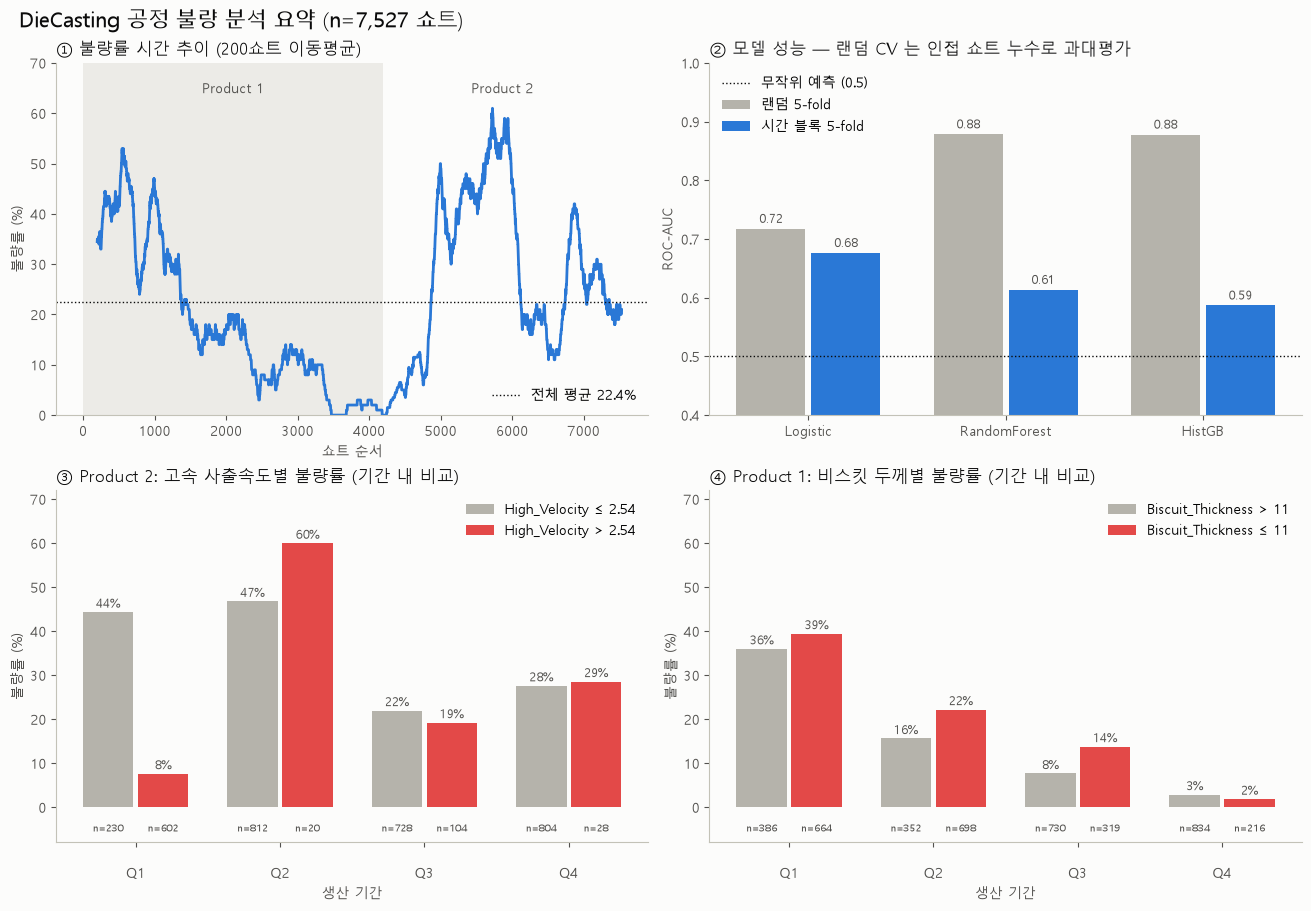

In [13]:
import os
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'font.size': 10,
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb'})
BLUE, ORANGE, RED, GRAY, INK, MUTED = '#2a78d6', '#eb6834', '#e34948', '#b5b3ab', '#0b0b0b', '#52514e'

fig, ax = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle(f'DieCasting 공정 불량 분석 요약 (n={len(df):,} 쇼트)', fontsize=15, color=INK, x=0.01, ha='left')

# ① 불량률 시간 추이
a = ax[0, 0]
a.axvspan(0, len(P1), color='#ecebe7', lw=0)
a.plot(df['shot'], roll * 100, color=BLUE, lw=2)
a.axhline(y.mean() * 100, color=INK, lw=1, ls=':', label=f'전체 평균 {y.mean():.1%}')
a.legend(frameon=False, loc='lower right')
a.text(len(P1) / 2, 64, 'Product 1', ha='center', color=MUTED)
a.text(len(P1) + len(P2) / 2, 64, 'Product 2', ha='center', color=MUTED)
a.set_ylim(0, 70)
a.set_title('① 불량률 시간 추이 (200쇼트 이동평균)', loc='left', color=INK)
a.set_xlabel('쇼트 순서'); a.set_ylabel('불량률 (%)')

# ② 랜덤 CV vs 시간 블록 CV
a = ax[0, 1]
pv = cv_res.pivot(index='model', columns='cv', values='ROC_AUC').loc[list(models)]
xx = np.arange(len(pv)); w = 0.38
for k, (col, color) in enumerate([('랜덤 5-fold', GRAY), ('시간 블록 5-fold', BLUE)]):
    a.bar(xx + (k - .5) * w, pv[col], w - 0.03, color=color, label=col)
    for xi, v in zip(xx + (k - .5) * w, pv[col]):
        a.text(xi, v + 0.01, f'{v:.2f}', ha='center', fontsize=9, color=MUTED)
a.axhline(0.5, color=INK, lw=1, ls=':', label='무작위 예측 (0.5)')
a.set_xticks(xx, pv.index); a.set_ylim(0.4, 1.0); a.set_ylabel('ROC-AUC')
a.set_title('② 모델 성능 — 랜덤 CV 는 인접 쇼트 누수로 과대평가', loc='left', color=INK)
a.legend(frameon=False, loc='upper left')

# ③ / ④ 기간 내 비교
def period_bars(a, s, mask, labels, title):
    t = s.groupby(['period', mask], observed=True)['Defect'].agg(['mean', 'size']).unstack()
    xx = np.arange(4); w = 0.38
    for k, (flag, color, lab) in enumerate([(False, GRAY, labels[0]), (True, RED, labels[1])]):
        rates = t['mean'].reindex(['Q1', 'Q2', 'Q3', 'Q4'])[flag] * 100
        ns = t['size'].reindex(['Q1', 'Q2', 'Q3', 'Q4'])[flag]
        a.bar(xx + (k - .5) * w, rates.fillna(0), w - 0.03, color=color, label=lab)
        for xi, v, n in zip(xx + (k - .5) * w, rates, ns):
            if pd.notna(v):
                a.text(xi, v + 1, f'{v:.0f}%', ha='center', fontsize=8.5, color=MUTED)
                a.text(xi, -5.5, f'n={n:.0f}', ha='center', fontsize=7.5, color=MUTED)
    a.set_xticks(xx, ['Q1', 'Q2', 'Q3', 'Q4']); a.tick_params(axis='x', pad=14)
    a.set_ylim(-8, 72); a.set_ylabel('불량률 (%)'); a.set_xlabel('생산 기간')
    a.set_title(title, loc='left', color=INK); a.legend(frameon=False, loc='upper right')

period_bars(ax[1, 0], P2, P2.High_Velocity > 2.54, ['High_Velocity ≤ 2.54', 'High_Velocity > 2.54'],
            '③ Product 2: 고속 사출속도별 불량률 (기간 내 비교)')
period_bars(ax[1, 1], P1, P1.Biscuit_Thickness <= 11, ['Biscuit_Thickness > 11', 'Biscuit_Thickness ≤ 11'],
            '④ Product 1: 비스킷 두께별 불량률 (기간 내 비교)')

os.makedirs('output', exist_ok=True)
fig.savefig('output/DieCasting_analysis_summary.png', dpi=150)
plt.show()

## 결론 요약
- **데이터**: 7,535 쇼트 × 18 변수, 결측 없음. `Velocity_1` 상수, 센서 0값 행 8개 제거 → 7,527 쇼트
- **불량률** 22.4% (Product 1: 17.6%, Product 2: 28.5%) — 제품은 연속 블록으로 생산 (P1 → P2)
- **데이터 구조 주의**: 직전 쇼트와 공정값이 동일한 행 약 42%, 불량 자기상관 0.49 → 랜덤 CV 는 누수
- **모델**: 랜덤 CV ROC-AUC ≈ 0.88 이지만 시간 블록 CV 는 0.58~0.68 → 공정 변수의 미래 예측력은 약함
- **불량률 드리프트**: Product 1 은 기간별 38% → 3% 로 감소 — 공정 변수보다 시기(로트·설비 상태) 영향이 큼
- **기간 내에서도 유지되는 신호**
  - Product 2: `High_Velocity > 2.54` 일 때 불량률 크게 낮음 (Q1 기준 7.6% vs 44.3%)
  - Product 1: `Biscuit_Thickness ≤ 11` 일 때 Q1~Q3 에서 일관되게 불량률 높음
- 관측 데이터이며 기간 교란이 크므로, 인과 확정에는 기간을 통제한 실험(DOE) 필요